# EN3160 Assignment 03

## Neural Network

---

**Name:** R.A.C.D. Ranawaka    
**Index Number:** 230526A  
**GitHub Link:** https://github.com/chaniruranawaka/Neural-Network

---

## Question 1 - Manually trained dense network on CIFAR-10

In [2]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

In [3]:
# 1. Dataloading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

testset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

classes = (
    'plane', 'car', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
)

print("Training images:", len(trainset))
print("Testing images:", len(testset))

Training images: 50000
Testing images: 10000


### (a) Add a 100-unit sigmoid hidden layer

The following cell defines the input, hidden, and output parameters. The hidden layer uses the sigmoid activation.

In [4]:
# 2. Define Network Parameters
Din = 3 * 32 * 32   # Input size (flattened CIFAR-10 image size)
H = 100             # Middle layer with 100 nodes
K = 10              # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize weights and biases
w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)

w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

# Hyperparameters
epochs = 10
lr = 0.1
lr_decay = 0.9
reg = 0
loss_history = []
epoch_losses = []

print("w1 shape:", w1.shape)
print("b1 shape:", b1.shape)
print("w2 shape:", w2.shape)
print("b2 shape:", b2.shape)

w1 shape: torch.Size([3072, 100])
b1 shape: torch.Size([100])
w2 shape: torch.Size([100, 10])
b2 shape: torch.Size([10])


### (b) Use cross-entropy loss

The training loop uses the cross-entropy loss on output logits and manually computes its gradients for backpropagation.

In [5]:
# 3. Training Loop
for t in range(epochs):
    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Forward pass
        z1 = x_train.mm(w1) + b1
        h1 = torch.sigmoid(z1)
        y_pred = h1.mm(w2) + b2

        # Cross-entropy loss
        loss = nn.functional.cross_entropy(y_pred, labels) + reg * (
            torch.sum(w1 * w1) + torch.sum(w2 * w2)
        )

        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        probs = torch.softmax(y_pred, dim=1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        dy_pred = (probs - y_train_onehot) / Ntr

        dw2 = h1.t().mm(dy_pred) + reg * w2
        db2 = dy_pred.sum(dim=0)

        dh1 = dy_pred.mm(w2.t())
        dz1 = dh1 * h1 * (1 - h1)

        dw1 = x_train.t().mm(dz1) + reg * w1
        db1 = dz1.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    epoch_loss = running_loss / len(trainloader)
    epoch_losses.append(epoch_loss)

    print(f"Epoch {t + 1}/{epochs}, Loss: {epoch_loss:.4f}")

    # Learning rate decay
    lr *= lr_decay

Epoch 1/10, Loss: 2.3026
Epoch 2/10, Loss: 2.3026
Epoch 3/10, Loss: 2.3026
Epoch 4/10, Loss: 2.3026
Epoch 5/10, Loss: 2.3026
Epoch 6/10, Loss: 2.3026
Epoch 7/10, Loss: 2.3026
Epoch 8/10, Loss: 2.3026
Epoch 9/10, Loss: 2.3026
Epoch 10/10, Loss: 2.3026


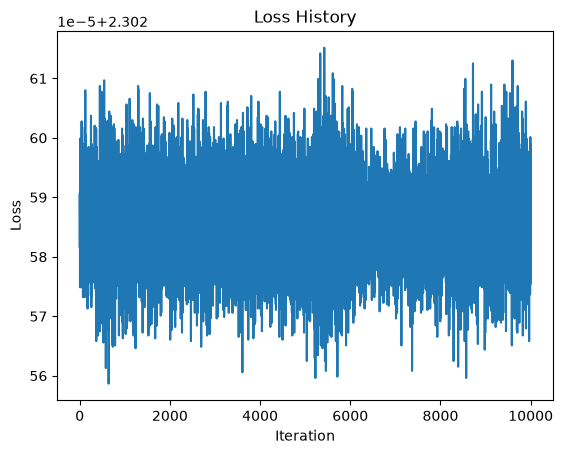

In [6]:
# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

### (c) Report accuracy after 10 epochs

The following cells calculate final accuracy on the training and test sets.

In [7]:
# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Forward pass
        z1 = x_train.mm(w1) + b1
        h1 = torch.sigmoid(z1)
        y_train_pred = h1.mm(w2) + b2

        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

Training accuracy: 10.00%


In [8]:
# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)

        # Forward pass
        z1 = x_test.mm(w1) + b1
        h1 = torch.sigmoid(z1)
        y_test_pred = h1.mm(w2) + b2

        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

Test accuracy: 10.00%


### Question 1 discussion

The hidden layer has 100 sigmoid units. The output layer returns logits, and cross-entropy computes the softmax internally. The manual output gradient is `(softmax(logits) - one_hot(labels)) / batch_size`, matching the mean cross-entropy loss. The test set is used only for final evaluation, not for parameter updates.

Run the training and evaluation cells to produce the 10-epoch training and test accuracies. A fully connected network on flattened CIFAR-10 images is expected to have limited accuracy because it does not preserve the images' spatial structure.

## Question 2 - CNN models for MNIST

The LeNet-5 model and the modern CNN use the same MNIST training and test splits. Both are trained for 10 epochs with cross-entropy loss. Each model's epoch output reports training and test loss and accuracy. The test set is reserved for evaluation.

In [ ]:
import copy
import numpy as np
import torch.nn.functional as F
from torch.utils.data import DataLoader

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])
mnist_train = torchvision.datasets.MNIST("./data", train=True, download=True, transform=mnist_transform)
mnist_test = torchvision.datasets.MNIST("./data", train=False, download=True, transform=mnist_transform)
mnist_trainloader = DataLoader(mnist_train, batch_size=128, shuffle=True, num_workers=0, pin_memory=(device.type == "cuda"))
mnist_testloader = DataLoader(mnist_test, batch_size=256, shuffle=False, num_workers=0, pin_memory=(device.type == "cuda"))
mnist_classes = [str(i) for i in range(10)]
mnist_epochs = 10

### Model definitions and shared evaluation helpers

The code below defines LeNet-5 and the three-convolution CNN, along with common training, plotting, and confusion-matrix functions.

In [ ]:
class LeNet5(nn.Module):
    """LeNet-5 style classifier for 28x28 MNIST images."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5), nn.Tanh(), nn.AvgPool2d(2),
            nn.Conv2d(6, 16, kernel_size=5), nn.Tanh(), nn.AvgPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(16 * 4 * 4, 120), nn.Tanh(),
            nn.Linear(120, 84), nn.Tanh(), nn.Linear(84, 10)
        )
    def forward(self, x):
        return self.classifier(self.features(x))


class SmallCNN(nn.Module):
    """Three convolution layers with batch normalization and dropout."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.MaxPool2d(2), nn.Dropout2d(0.10),
            nn.Conv2d(32, 64, 3, padding=1, bias=False), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(2), nn.Dropout2d(0.15),
            nn.Conv2d(64, 128, 3, padding=1, bias=False), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.30), nn.Linear(128, 10))
    def forward(self, x):
        return self.classifier(self.features(x))


def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum = 0.0
    correct = 0
    count = 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
            batch_count = labels.size(0)
            loss_sum += loss.item() * batch_count
            correct += (logits.argmax(1) == labels).sum().item()
            count += batch_count
    return loss_sum / count, 100.0 * correct / count


def fit_classifier(model, trainloader, testloader, epochs, lr=1e-3):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
    for epoch in range(epochs):
        train_loss, train_acc = run_epoch(model, trainloader, criterion, optimizer)
        test_loss, test_acc = run_epoch(model, testloader, criterion)
        for key, value in zip(history, (train_loss, train_acc, test_loss, test_acc)):
            history[key].append(value)
        print(f"Epoch {epoch + 1:02d}/{epochs}: train loss {train_loss:.4f}, train acc {train_acc:.2f}% | test loss {test_loss:.4f}, test acc {test_acc:.2f}%")
    return model, history


def plot_history(history, title):
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history["train_loss"], marker="o", label="Train")
    axes[0].plot(epochs, history["test_loss"], marker="o", label="Test")
    axes[0].set(title=f"{title}: loss", xlabel="Epoch", ylabel="Cross-entropy loss")
    axes[0].legend(); axes[0].grid(True, alpha=0.3)
    axes[1].plot(epochs, history["train_acc"], marker="o", label="Train")
    axes[1].plot(epochs, history["test_acc"], marker="o", label="Test")
    axes[1].set(title=f"{title}: accuracy", xlabel="Epoch", ylabel="Accuracy (%)")
    axes[1].legend(); axes[1].grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()


def get_confusion_matrix(model, loader, num_classes=10):
    matrix = torch.zeros(num_classes, num_classes, dtype=torch.int64)
    model.eval()
    with torch.no_grad():
        for images, labels in loader:
            predictions = model(images.to(device)).argmax(1).cpu()
            ids = labels * num_classes + predictions
            matrix += torch.bincount(ids, minlength=num_classes ** 2).reshape(num_classes, num_classes)
    return matrix.numpy()


def show_confusion_matrix(matrix, class_names, title):
    fig, ax = plt.subplots(figsize=(8, 7))
    image = ax.imshow(matrix, cmap="Blues")
    ax.set(title=title, xlabel="Predicted label", ylabel="True label")
    ax.set_xticks(range(len(class_names)), class_names, rotation=45)
    ax.set_yticks(range(len(class_names)), class_names)
    fig.colorbar(image, ax=ax, label="Number of images")
    threshold = matrix.max() / 2
    for row in range(matrix.shape[0]):
        for col in range(matrix.shape[1]):
            ax.text(col, row, str(matrix[row, col]), ha="center", va="center",
                    color="white" if matrix[row, col] > threshold else "black", fontsize=8)
    plt.tight_layout(); plt.show()

### (a) Train LeNet-5 for 10 epochs

In [ ]:
lenet_model, lenet_history = fit_classifier(
    LeNet5(), mnist_trainloader, mnist_testloader, mnist_epochs
)
print(
    f"LeNet-5 final: train accuracy = {lenet_history['train_acc'][-1]:.2f}%, "
    f"test accuracy = {lenet_history['test_acc'][-1]:.2f}%"
)

### (b) Train the modern three-layer CNN for 10 epochs

In [ ]:
smallcnn_model, smallcnn_history = fit_classifier(
    SmallCNN(), mnist_trainloader, mnist_testloader, mnist_epochs
)
print(
    f"Three-layer CNN final: train accuracy = {smallcnn_history['train_acc'][-1]:.2f}%, "
    f"test accuracy = {smallcnn_history['test_acc'][-1]:.2f}%"
)

### (c) Plot epoch metrics and show test confusion matrices

The plots below show training and test loss and accuracy for both models. Each confusion matrix is computed on the held-out MNIST test set.

In [ ]:
plot_history(lenet_history, "LeNet-5 on MNIST")
lenet_cm = get_confusion_matrix(lenet_model, mnist_testloader)
show_confusion_matrix(lenet_cm, mnist_classes, "LeNet-5 test confusion matrix")

plot_history(smallcnn_history, "Three-layer CNN on MNIST")
smallcnn_cm = get_confusion_matrix(smallcnn_model, mnist_testloader)
show_confusion_matrix(smallcnn_cm, mnist_classes, "Three-layer CNN test confusion matrix")

### Question 2 discussion

Compare the final training and test accuracy values and the two learning curves. In each confusion matrix, rows are true digits and columns are predicted digits. Counts concentrated on the diagonal indicate correct predictions; off-diagonal counts show which digits the model confuses. Batch normalization stabilizes the modern CNN's activations, while dropout helps reduce overfitting. The exact values are printed when the notebook is run and may vary slightly by environment.

## Question 3 - Transfer learning with ImageNet-pretrained ResNet-18

This section follows the [PyTorch transfer learning tutorial](https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html) and uses its Hymenoptera ants-and-bees dataset. Both approaches start from ImageNet-1K pretrained weights and use the same data split and image transforms. Validation accuracy and loss are reported by epoch.

In [ ]:
import os
import urllib.request
import zipfile
from pathlib import Path
from torchvision import models

data_root = Path("./data/hymenoptera_data")
archive = Path("./data/hymenoptera_data.zip")
if not data_root.exists():
    archive.parent.mkdir(parents=True, exist_ok=True)
    if not archive.exists():
        urllib.request.urlretrieve(
            "https://download.pytorch.org/tutorial/hymenoptera_data.zip", archive
        )
    with zipfile.ZipFile(archive, "r") as zip_ref:
        zip_ref.extractall(archive.parent)

data_transforms = {
    "train": transforms.Compose([
        transforms.RandomResizedCrop(224), transforms.RandomHorizontalFlip(),
        transforms.ToTensor(), transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    "val": transforms.Compose([
        transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
}
image_datasets = {
    split: torchvision.datasets.ImageFolder(data_root / split, data_transforms[split])
    for split in ("train", "val")
}
image_loaders = {
    split: DataLoader(image_datasets[split], batch_size=8, shuffle=(split == "train"),
                      num_workers=0, pin_memory=(device.type == "cuda"))
    for split in ("train", "val")
}
class_names = image_datasets["train"].classes
dataset_sizes = {split: len(image_datasets[split]) for split in image_datasets}
print("Classes:", class_names, "| split sizes:", dataset_sizes)

In [ ]:
def make_resnet18(feature_extraction=False):
    # DEFAULT selects the current torchvision ImageNet-1K pretrained weights.
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    if feature_extraction:
        for parameter in model.parameters():
            parameter.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, len(class_names))
    return model.to(device)


def train_transfer_model(model, trainable_parameters, epochs=10, lr=1e-3, freeze_backbone=False):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(trainable_parameters, lr=lr, momentum=0.9)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_weights = copy.deepcopy(model.state_dict())
    best_val = 0.0
    for epoch in range(epochs):
        for split in ("train", "val"):
            training = split == "train"
            model.train(training)
            if training and freeze_backbone:
                model.eval()
                model.fc.train()
            loss_sum = 0.0
            correct = 0
            count = 0
            context = torch.enable_grad() if training else torch.no_grad()
            with context:
                for images, labels in image_loaders[split]:
                    images, labels = images.to(device), labels.to(device)
                    if training:
                        optimizer.zero_grad(set_to_none=True)
                    logits = model(images)
                    loss = criterion(logits, labels)
                    if training:
                        loss.backward()
                        optimizer.step()
                    n = labels.size(0)
                    loss_sum += loss.item() * n
                    correct += (logits.argmax(1) == labels).sum().item()
                    count += n
            epoch_loss = loss_sum / count
            epoch_acc = 100.0 * correct / count
            history[f"{split}_loss"].append(epoch_loss)
            history[f"{split}_acc"].append(epoch_acc)
            if split == "val" and epoch_acc > best_val:
                best_val = epoch_acc
                best_weights = copy.deepcopy(model.state_dict())
        scheduler.step()
        print(f"Epoch {epoch + 1:02d}/{epochs}: train loss {history['train_loss'][-1]:.4f}, train acc {history['train_acc'][-1]:.2f}% | val loss {history['val_loss'][-1]:.4f}, val acc {history['val_acc'][-1]:.2f}%")
    model.load_state_dict(best_weights)
    return model, history, best_val


def plot_transfer_history(history, title):
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history["train_loss"], marker="o", label="Train")
    axes[0].plot(epochs, history["val_loss"], marker="o", label="Validation")
    axes[0].set(title=f"{title}: loss", xlabel="Epoch", ylabel="Cross-entropy loss"); axes[0].legend(); axes[0].grid(True, alpha=.3)
    axes[1].plot(epochs, history["train_acc"], marker="o", label="Train")
    axes[1].plot(epochs, history["val_acc"], marker="o", label="Validation")
    axes[1].set(title=f"{title}: accuracy", xlabel="Epoch", ylabel="Accuracy (%)"); axes[1].legend(); axes[1].grid(True, alpha=.3)
    plt.tight_layout(); plt.show()

### (a) Fine tune the pretrained ResNet-18

All ResNet-18 parameters, including the replacement two-class output layer, are trainable.

In [ ]:
finetune_model = make_resnet18(feature_extraction=False)
finetune_model, finetune_history, finetune_best_val = train_transfer_model(
    finetune_model, finetune_model.parameters(), epochs=10, lr=1e-3
)
plot_transfer_history(finetune_history, "ResNet-18 fine tuning")
print(f"Fine tuning: best validation accuracy = {finetune_best_val:.2f}%")

### (b) Use ResNet-18 as a fixed feature extractor

The pretrained backbone remains frozen, including its batch-normalization statistics. Only the new output layer is trained.

In [ ]:
feature_model = make_resnet18(feature_extraction=True)
feature_model, feature_history, feature_best_val = train_transfer_model(
    feature_model, feature_model.fc.parameters(), epochs=10, lr=1e-3, freeze_backbone=True
)
plot_transfer_history(feature_history, "ResNet-18 feature extraction")
print(f"Feature extraction: best validation accuracy = {feature_best_val:.2f}%")

### Question 3 discussion

Compare the best validation accuracy and learning curves from the two approaches. Fine tuning updates the ResNet backbone and the new classifier. Feature extraction keeps the pretrained backbone fixed and trains only the final classifier. The validation set is small, so its accuracy may fluctuate between epochs; the best validation checkpoint is restored at the end of each run. Record the printed best validation accuracies and the CPU or GPU used in the report.